In [1]:
import numpy as np
import librosa
import os
from pesq import pesq
from pystoi import stoi
import mir_eval
from scipy.signal import lfilter, wiener
import matplotlib.pyplot as plt
import IPython.display as ipd
import soundfile as sf

In [2]:

def spectral_subtraction(noisy_signal, noise_estimate, alpha=1.0, beta=0.002):
    # Ensure noise_estimate is the same length as noisy_signal
    if len(noise_estimate) < len(noisy_signal):
        noise_estimate = np.pad(noise_estimate, (0, len(noisy_signal) - len(noise_estimate)), 'constant')
    else:
        noise_estimate = noise_estimate[:len(noisy_signal)]
    
    noisy_stft = librosa.stft(noisy_signal)
    noise_stft = librosa.stft(noise_estimate)
    
    noisy_mag, noisy_phase = librosa.magphase(noisy_stft)
    noise_mag, _ = librosa.magphase(noise_stft)
    
    # Spectral subtraction
    subtracted_mag = np.maximum(noisy_mag - alpha * noise_mag, beta * noise_mag)
    
    # Reconstruct the signal
    subtracted_stft = subtracted_mag * noisy_phase
    denoised_signal = librosa.istft(subtracted_stft)
    
    return denoised_signal

In [3]:
def denoise_spec_wiener(noisy_audio):

    # Estimate noise from the beginning of the noisy audio
    noise_estimate = noisy_audio[:8000]  # Assuming the first second is noise

    # Apply Wiener filter
    wiener_denoised = wiener(noisy_audio)

    # Apply Spectral Subtraction
    spectral_denoised = spectral_subtraction(noisy_audio, noise_estimate)

    return wiener_denoised, spectral_denoised

In [4]:
def calculate_sdr(clean_audio, denoised_audio):    
    # Calculate SDR
    signal_power = np.sum(clean_audio ** 2)
    noise_power = np.sum((clean_audio - denoised_audio) ** 2)
    sdr = 10 * np.log10(signal_power / noise_power)
    
    return sdr

def calculate_sdr_freq_domain(clean_audio, denoised_audio, n_fft=256, hop_length=64):

    # Calculate SDR for each frequency band
    clean_stft    = librosa.stft(clean_audio, n_fft=n_fft, hop_length=hop_length, win_length=n_fft, window='hamming', center=True)
    denoised_stft = librosa.stft(denoised_audio, n_fft=n_fft, hop_length=hop_length, win_length=n_fft, window='hamming', center=True)

    print('clean_stft =', clean_stft.shape)
    
    sdr_freq = []
    for i in range(clean_stft.shape[1]):
        signal_power = np.sum(np.abs(clean_stft[:, i]) ** 2)
        noise_power = np.sum(np.abs(clean_stft[:, i] - denoised_stft[:, i]) ** 2)
        sdr_freq.append(abs( 10 * np.log10(signal_power / noise_power)) )
    
    print('sdr_freq size =', len(sdr_freq))

    average_sdr = np.mean(sdr_freq)

    return average_sdr

def calculate_sdr_magnitude(clean_audio, denoised_audio, n_fft=256, hop_length=64):

    # Calculate SDR for each frequency band
    clean_stft = librosa.stft(clean_audio, n_fft=n_fft, hop_length=hop_length)
    denoised_stft = librosa.stft(denoised_audio, n_fft=n_fft, hop_length=hop_length)
    
    reference_mag = np.abs(clean_stft)
    estimated_mag = np.abs(denoised_stft)

    print('reference.shape = ', reference_mag.shape())

    # Calculate SDR using mir_eval
    sdr, _, _, _ = mir_eval.separation.bss_eval_sources(reference_mag, estimated_mag)

    sdr = sdr[0]
    
    return sdr

In [5]:
def evaluate_performance(clean_audio, denoised_audio, sr=8000):

    # Ensure both signals have the same length
    min_len = min(len(clean_audio), len(denoised_audio))
    clean_audio = clean_audio[:min_len]
    denoised_audio = denoised_audio[:min_len]

    # PESQ
    pesq_score = pesq(sr, clean_audio, denoised_audio, 'nb')
    
    # STOI
    stoi_score = stoi(clean_audio, denoised_audio, sr, extended=False)
    
    # SDR (Using mir_eval)
    sdr, _, _, _ = mir_eval.separation.bss_eval_sources(clean_audio, denoised_audio)
    sdr = sdr[0]
    # sdr = calculate_sdr(clean_audio, denoised_audio)

    # sdr = calculate_sdr_freq_domain(clean_audio, denoised_audio)
    
    # SNR
    def calculate_snr(clean, denoised):
        noise = clean - denoised
        snr = 10 * np.log10(np.sum(clean**2) / np.sum(noise**2))
        return snr
    
    snr_score = calculate_snr(clean_audio, denoised_audio)
    
    # Log-Spectral Distance (LSD)
    def log_spectral_distance(clean, denoised, sr, n_fft=256, hop_length=64):
        clean_mag, _ = librosa.magphase(librosa.stft(clean, n_fft=n_fft, hop_length=hop_length))
        denoised_mag, _ = librosa.magphase(librosa.stft(denoised, n_fft=n_fft, hop_length=hop_length))
        
        clean_db = librosa.amplitude_to_db(clean_mag)
        denoised_db = librosa.amplitude_to_db(denoised_mag)
        
        lsd = np.mean(np.sqrt(np.mean((clean_db - denoised_db) ** 2, axis=0)))
        return lsd
    lsd_score = log_spectral_distance(clean_audio, denoised_audio, sr)
    
    return {
        "PESQ": pesq_score,
        "STOI": stoi_score,
        "SDR": sdr,
        "SNR": snr_score,
        "LSD": lsd_score
    }

In [6]:
def plot_spectrograms(original_audio, noisy_audio, denoised_audio, sr=8000, n_fft=256, hop_length=64):
    plt.figure(figsize=(15, 10))

    # Compute STFT
    def get_spectrogram(audio):
        stft = librosa.stft(audio, n_fft=n_fft, hop_length=hop_length)
        magnitude, _ = librosa.magphase(stft)
        return magnitude

    original_mag = get_spectrogram(original_audio)
    noisy_mag = get_spectrogram(noisy_audio)
    denoised_mag = get_spectrogram(denoised_audio)

    # Convert to dB
    original_db = librosa.amplitude_to_db(original_mag, ref=np.max)
    noisy_db = librosa.amplitude_to_db(noisy_mag, ref=np.max)
    denoised_db = librosa.amplitude_to_db(denoised_mag, ref=np.max)

    plt.subplot(3, 1, 1)
    plt.imshow(original_db, aspect='auto', cmap='Greens', origin='lower')
    plt.title('Original Audio Spectrogram')
    plt.colorbar(format='%+2.0f dB')

    plt.subplot(3, 1, 2)
    plt.imshow(noisy_db, aspect='auto', cmap='Reds', origin='lower')
    plt.title('Noisy Audio Spectrogram')
    plt.colorbar(format='%+2.0f dB')

    plt.subplot(3, 1, 3)
    plt.imshow(denoised_db, aspect='auto', cmap='Blues', origin='lower')
    plt.title('Denoised Audio Spectrogram')
    plt.colorbar(format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

In [7]:
# Loading and evaluating audio
#clean_audio = librosa.load('dataset/CleanSpeech_training/clnsp1.wav', sr=16000)
#noisy_audio = librosa.load('dataset/NoisySpeech_training/noisy1_SNRdb_0.0_clnsp1.wav', sr=16000)
#denoised_audio = librosa.load('dataset/DenoisedSpeech_training/SNR_0.0db/denoised_SNRdb_0.0_clnsp1.wav', sr=8000)

clean_audio = librosa.load('test_saga/clnsp1.wav', sr=16000)
noisy_audio = librosa.load('test_saga/noisy.wav', sr=16000)
denoised_audio = librosa.load('new/enhanced/enhanced_noisy.wav', sr=8000)


clean_audio = librosa.resample(clean_audio[0], orig_sr=16000, target_sr=8000)
noisy_audio = librosa.resample(noisy_audio[0], orig_sr=16000, target_sr=8000)

# sf.write('resampled_clean.wav', clean_audio, samplerate=8000, format='WAV', subtype='PCM_16')

wiener_denoised, spectral_denoised = denoise_spec_wiener(noisy_audio)

print('CNN Denoising')
print(evaluate_performance(clean_audio, denoised_audio[0]))
print('\nWiener Denoising')
print(evaluate_performance(clean_audio, wiener_denoised))
print('\nSpectral Subtraction')
print(evaluate_performance(clean_audio, spectral_denoised))
print('\nOriginal noisy\n', evaluate_performance(clean_audio, noisy_audio))

# Play clean audio
print("Clean Audio:")
ipd.display(ipd.Audio(clean_audio, rate=8000))

# Play noisy audio
print("Noisy Audio:")
ipd.display(ipd.Audio(noisy_audio, rate=8000))

# play CNN denoised audio
print("CNN Denoised Audio:")
ipd.display(ipd.Audio(denoised_audio[0], rate=8000))

# Play Wiener denoised audio
print("Wiener Denoised Audio:")
ipd.display(ipd.Audio(wiener_denoised, rate=8000))

# Play Spectral Subtraction denoised audio
print("Spectral Subtraction Denoised Audio:")
ipd.display(ipd.Audio(spectral_denoised, rate=8000))

CNN Denoising
{'PESQ': 2.472247362136841, 'STOI': 0.7409776145185462, 'SDR': 0.15811055303029575, 'SNR': 2.2947894036769867, 'LSD': 12.836246}

Wiener Denoising
{'PESQ': 2.422288179397583, 'STOI': 0.7209807678190396, 'SDR': -0.09546906730959563, 'SNR': -0.10354129745153759, 'LSD': 14.34089674724569}

Spectral Subtraction
{'PESQ': 1.9693455696105957, 'STOI': 0.7200003741930012, 'SDR': 0.059138085249865704, 'SNR': 0.6092673540115356, 'LSD': 15.165763}

Original noisy
 {'PESQ': 2.423091173171997, 'STOI': 0.7412798413843272, 'SDR': 0.06937659391372777, 'SNR': -0.12057571671903133, 'LSD': 15.502431}
Clean Audio:


Noisy Audio:


CNN Denoised Audio:


Wiener Denoised Audio:


Spectral Subtraction Denoised Audio:


Salvar como csv

In [21]:
import pandas as pd

# Get all clean speech files
clean_files = sorted([f for f in os.listdir('dataset/CleanSpeech_training') if f.endswith('.wav')])
noisy_files = sorted([f for f in os.listdir('dataset/NoisySpeech_training') if f.endswith('.wav') and 'SNRdb_0.0' in f])
denoised_files = sorted([f for f in os.listdir('dataset/DenoisedSpeech_training/SNR_0.0db') if f.endswith('.wav')])

results = []

for clean_f, noisy_f, denoised_f in zip(clean_files, noisy_files, denoised_files):

    # Extract the audio number from the clean file name (remove 'clnsp' and '.wav')
    clean_num = clean_f.replace('clnsp', '').replace('.wav', '')
    expected_noisy = f'noisy{clean_num}_SNRdb_0.0_clnsp{clean_num}.wav'
    expected_denoised = f'denoised_SNRdb_0.0_clnsp{clean_num}.wav'

    if denoised_f != expected_denoised:
        print(f"Warning: File names don't match expected pattern:")
        print(f"Clean: {clean_f}")
        print(f"Expected noisy: {expected_noisy}, Got: {noisy_f}")
        print(f"Expected denoised: {expected_denoised}, Got: {denoised_f}")
        continue

    # Load audio files
    clean = librosa.load(os.path.join('dataset/CleanSpeech_training', clean_f), sr=16000)[0]
    noisy = librosa.load(os.path.join('dataset/NoisySpeech_training', expected_noisy), sr=16000)[0]
    denoised = librosa.load(os.path.join('dataset/DenoisedSpeech_training/SNR_0.0db', denoised_f), sr=8000)
    
    # Resample clean audio
    clean = librosa.resample(clean, orig_sr=16000, target_sr=8000)
    noisy = librosa.resample(noisy, orig_sr=16000, target_sr=8000)

    print('Clean:', clean_f)
    print('Noisy:', expected_noisy)
    print('Denoised:', denoised_f)

    # Apply Wiener and Spectral Subtraction
    wiener_den, spectral_den = denoise_spec_wiener(noisy)
    
    # Evaluate all methods
    result = {
        'filename': clean_f,
        'CNN': evaluate_performance(clean, denoised[0]),
        'Wiener': evaluate_performance(clean, wiener_den),
        'Spectral': evaluate_performance(clean, spectral_den),
        'Noisy': evaluate_performance(clean, noisy)
    }
    results.append(result)

# Create a flattened version of the results
flat_results = []
for r in results:
    flat_dict = {'filename': r['filename']}
    
    # For each method (CNN, Wiener, Spectral, Noisy)
    for method in ['CNN', 'Wiener', 'Spectral', 'Noisy']:
        # For each metric (PESQ, STOI, SDR, SNR, LSD)
        for metric, value in r[method].items():
            flat_dict[f'{method}_{metric}'] = value
    
    flat_results.append(flat_dict)

# Create new dataframe with flattened structure
df = pd.DataFrame(flat_results)

# Save results to CSV
df.to_csv('denoising_results_20.0.csv', index=False)

Clean: clnsp1.wav
Noisy: noisy1_SNRdb_0.0_clnsp1.wav
Denoised: denoised_SNRdb_0.0_clnsp1.wav
Clean: clnsp10.wav
Noisy: noisy10_SNRdb_0.0_clnsp10.wav
Denoised: denoised_SNRdb_0.0_clnsp10.wav
Clean: clnsp100.wav
Noisy: noisy100_SNRdb_0.0_clnsp100.wav
Denoised: denoised_SNRdb_0.0_clnsp100.wav
Clean: clnsp101.wav
Noisy: noisy101_SNRdb_0.0_clnsp101.wav
Denoised: denoised_SNRdb_0.0_clnsp101.wav
Clean: clnsp102.wav
Noisy: noisy102_SNRdb_0.0_clnsp102.wav
Denoised: denoised_SNRdb_0.0_clnsp102.wav
Clean: clnsp103.wav
Noisy: noisy103_SNRdb_0.0_clnsp103.wav
Denoised: denoised_SNRdb_0.0_clnsp103.wav
Clean: clnsp104.wav
Noisy: noisy104_SNRdb_0.0_clnsp104.wav
Denoised: denoised_SNRdb_0.0_clnsp104.wav
Clean: clnsp105.wav
Noisy: noisy105_SNRdb_0.0_clnsp105.wav
Denoised: denoised_SNRdb_0.0_clnsp105.wav
Clean: clnsp106.wav
Noisy: noisy106_SNRdb_0.0_clnsp106.wav
Denoised: denoised_SNRdb_0.0_clnsp106.wav
Clean: clnsp107.wav
Noisy: noisy107_SNRdb_0.0_clnsp107.wav
Denoised: denoised_SNRdb_0.0_clnsp107.wav
Cl

/home/ayanami/.local/lib/python3.10/site-packages/scipy/signal/_signaltools.py:1657: RuntimeWarning: divide by zero encountered in divide
  res *= (1 - noise / lVar)
/home/ayanami/.local/lib/python3.10/site-packages/scipy/signal/_signaltools.py:1657: RuntimeWarning: invalid value encountered in multiply
  res *= (1 - noise / lVar)


Clean: clnsp255.wav
Noisy: noisy255_SNRdb_0.0_clnsp255.wav
Denoised: denoised_SNRdb_0.0_clnsp255.wav
Clean: clnsp256.wav
Noisy: noisy256_SNRdb_0.0_clnsp256.wav
Denoised: denoised_SNRdb_0.0_clnsp256.wav
Clean: clnsp257.wav
Noisy: noisy257_SNRdb_0.0_clnsp257.wav
Denoised: denoised_SNRdb_0.0_clnsp257.wav
Clean: clnsp258.wav
Noisy: noisy258_SNRdb_0.0_clnsp258.wav
Denoised: denoised_SNRdb_0.0_clnsp258.wav
Clean: clnsp259.wav
Noisy: noisy259_SNRdb_0.0_clnsp259.wav
Denoised: denoised_SNRdb_0.0_clnsp259.wav
Clean: clnsp26.wav
Noisy: noisy26_SNRdb_0.0_clnsp26.wav
Denoised: denoised_SNRdb_0.0_clnsp26.wav
Clean: clnsp260.wav
Noisy: noisy260_SNRdb_0.0_clnsp260.wav
Denoised: denoised_SNRdb_0.0_clnsp260.wav
Clean: clnsp261.wav
Noisy: noisy261_SNRdb_0.0_clnsp261.wav
Denoised: denoised_SNRdb_0.0_clnsp261.wav
Clean: clnsp262.wav
Noisy: noisy262_SNRdb_0.0_clnsp262.wav
Denoised: denoised_SNRdb_0.0_clnsp262.wav
Clean: clnsp263.wav
Noisy: noisy263_SNRdb_0.0_clnsp263.wav
Denoised: denoised_SNRdb_0.0_clnsp26

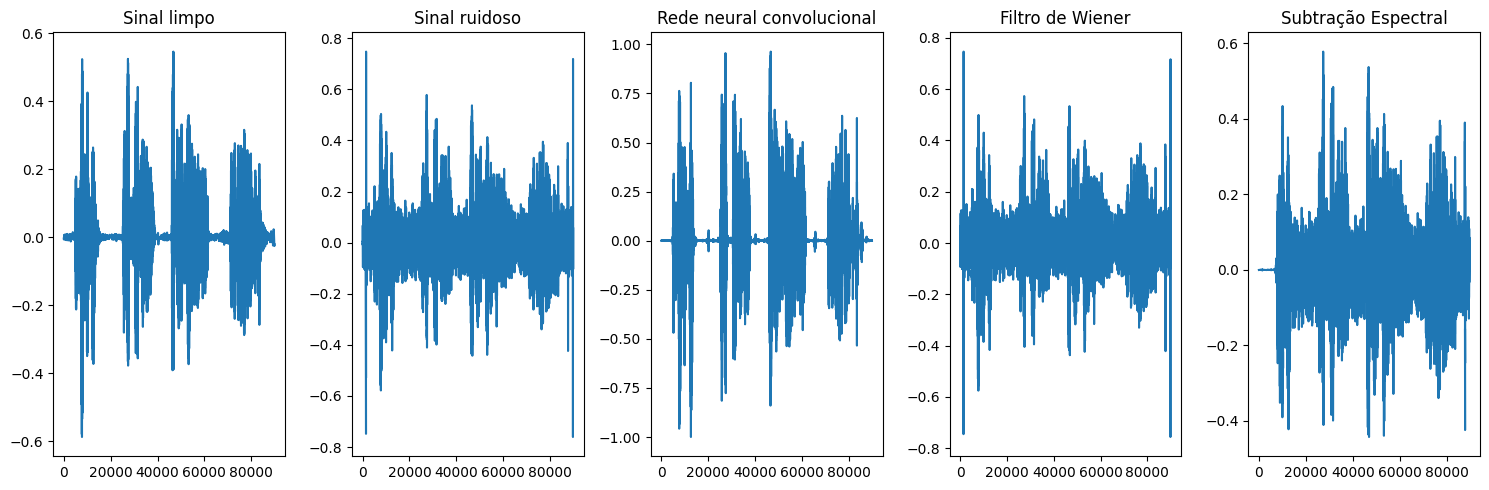

In [9]:

# Plot the results
plt.figure(figsize=(15, 5))
plt.subplot(1, 5, 1)
plt.plot(clean_audio)
plt.title('Sinal limpo')

plt.subplot(1, 5, 2)
plt.plot(noisy_audio)
plt.title('Sinal ruidoso')

plt.subplot(1, 5, 3)
plt.plot(denoised_audio[0])
plt.title('Rede neural convolucional')

plt.subplot(1, 5, 4)
plt.plot(wiener_denoised)
plt.title('Filtro de Wiener')

plt.subplot(1, 5, 5)
plt.plot(spectral_denoised)
plt.title('Subtração Espectral')

plt.tight_layout()
plt.show()


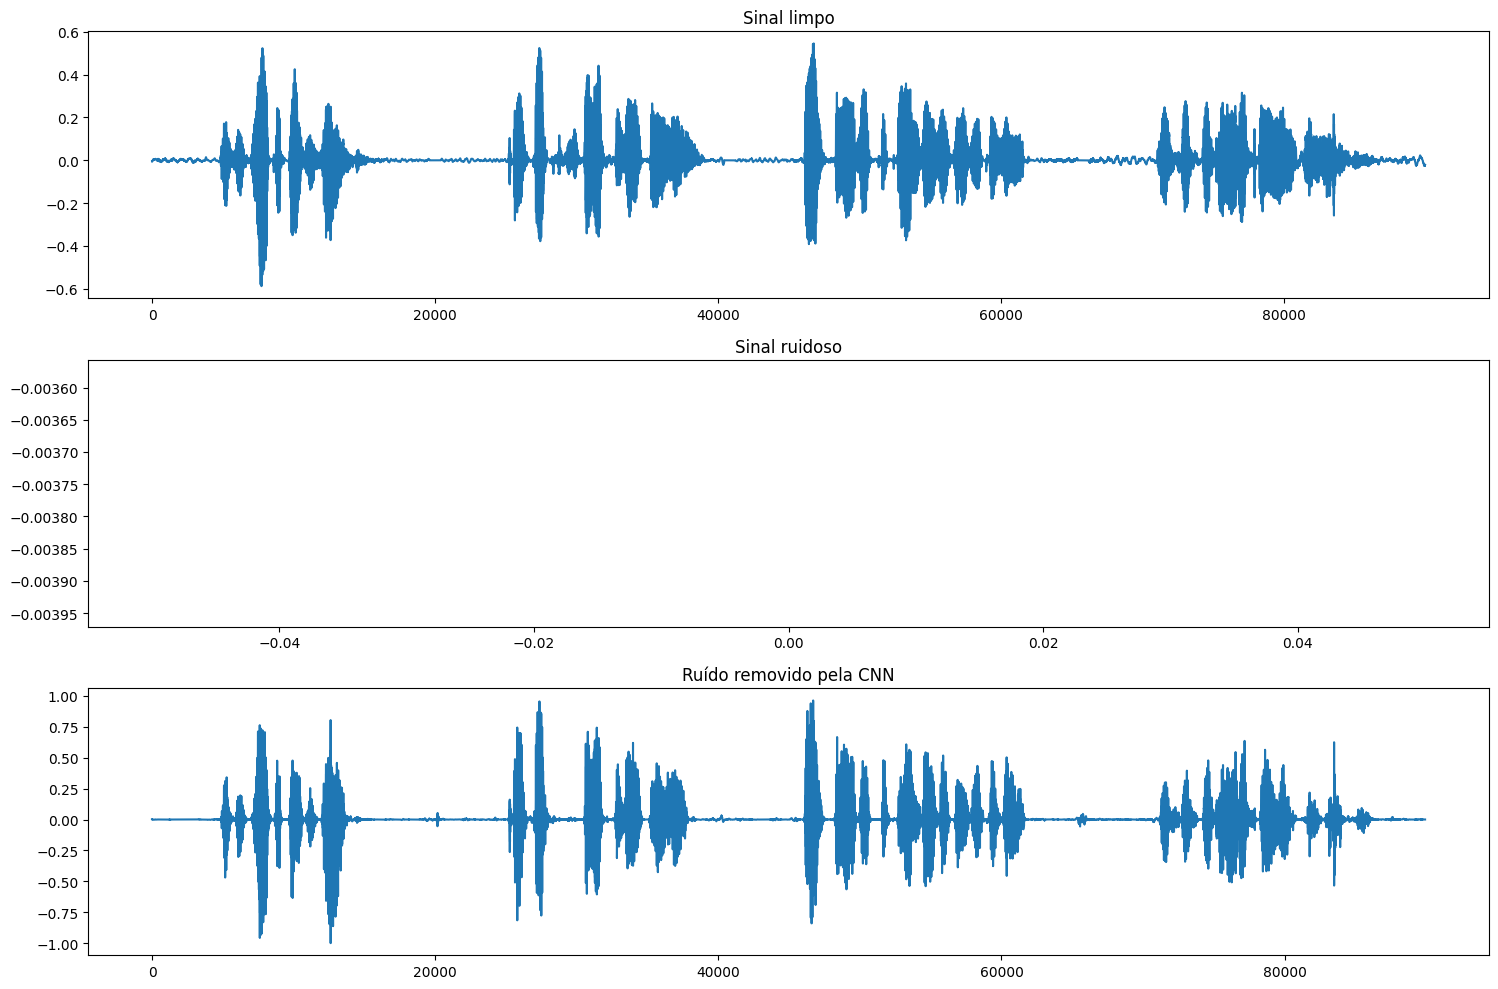

In [10]:
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(clean_audio)
plt.title('Sinal limpo')

plt.subplot(3, 1, 2)
plt.plot(noisy_audio[0])
plt.title('Sinal ruidoso')

plt.subplot(3, 1, 3)
plt.plot(denoised_audio[0])
plt.title('Ruído removido pela CNN')

plt.tight_layout()
plt.show()

In [ ]:
print('CNN Denoising')
print(evaluate_performance(clean_audio, denoised_audio[0]))
print('\nWiener Denoising')
print(evaluate_performance(clean_audio, wiener_denoised))
print('\nSpectral Subtraction')
print(evaluate_performance(clean_audio, spectral_denoised))
print('\nOriginal noisy\n', evaluate_performance(clean_audio, noisy_audio))

CNN Denoising
{'PESQ': 2.1579437255859375, 'STOI': 0.7015952690567135, 'SDR': 6.592752688484419, 'SNR': 2.6603856682777405, 'LSD': 9.681494}

Wiener Denoising
{'PESQ': 2.422288179397583, 'STOI': 0.7209807678190396, 'SDR': -0.09546906730959563, 'SNR': -0.10354129745153759, 'LSD': 14.34089674724569}

Spectral Subtraction
{'PESQ': 1.9693455696105957, 'STOI': 0.7200003741930012, 'SDR': 0.059138085249865704, 'SNR': 0.6092673540115356, 'LSD': 15.165763}


TypeError: object of type 'numpy.float32' has no len()